# Pair 4: Learned image compression, HPCM-Base (System A) vs DCAE (System B)

We serve about 50 million product image views a month as JPEG through a CDN. Smaller files mean a smaller CDN bill and
faster pages on mobile, as long as the detail a shopper zooms into survives. Learned codecs claim large savings over
JPEG. How large on our photos, and can we actually ship them?

Both models are VAE-style codecs (Balle et al., 2018, week 9): an encoder maps the image to a quantised latent, an
entropy model gives each latent value a probability so it can be stored in few bits, and a decoder rebuilds the image.
Training minimises rate + lambda x distortion, a weighted form of the ELBO. They differ in the entropy model:
- System A, HPCM-Base (Li et al., 2025): hierarchical progressive context model.
- System B, DCAE (Lu et al., CVPR 2025): dictionary-based cross-attention entropy model.
- Baselines: JPEG, WebP and AVIF, the formats browsers can show today.

8 product photos and the 24 Kodak images, 4 rate points per learned codec (the authors' MSE checkpoints) and 9 quality
levels per standard codec, all written as real files. I report rate-distortion curves, BD-rate, whether my Kodak
results match each paper, speed, a cross-device decode test, CDN cost and governance. Codecs are deterministic, so
instead of seeds the reproducibility check is against the papers' own numbers.

To run on Kaggle: GPU T4 x2, Internet on, then Save & Run All (about 35 min, including 6.8 GB of checkpoints from
Google Drive). If Drive refuses a download, add the .pth files as a Kaggle dataset; the notebook looks there first.

## Setup
Install the pinned packages, import the libraries and fix the rate points (lambdas) and quality levels.

In [ ]:
# install the pinned versions used for this run
import subprocess, sys
from importlib.metadata import version
# compressai 1.2.8 asks for numpy<2, which would break pandas, so it goes in without its dependencies
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"numpy=={version('numpy')}", "pybind11>=2.13", "pytorch-msssim==1.0.0",
                "imagecodecs==2026.1.14", "gdown>=5.2", "timm>=1.0", "einops", "torch-geometric", "tomli"], check=True, capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "compressai==1.2.8"], check=True, capture_output=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--no-deps', 'compressai==1.2.8'], returncode=0, stdout=b'', stderr=b'')

In [ ]:
# libraries
import csv, gzip, hashlib, importlib, json, math, random, shutil, struct, time, urllib.request
from pathlib import Path

import imagecodecs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage
from scipy.interpolate import PchipInterpolator
from scipy.stats import wilcoxon

# output folder, codec names, the four MSE checkpoints per codec and the quality levels for JPEG, WebP and AVIF
OUT = Path("/kaggle/working/pair4")
OUT.mkdir(parents=True, exist_ok=True)
A, B = "HPCM-Base", "DCAE"
LAMBDAS = ["0.0035", "0.0067", "0.013", "0.025"]
QUALITY = [10, 20, 30, 40, 50, 60, 70, 80, 90]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(torch.cuda.get_device_name(0))

Tesla T4


## Code and checkpoints
Both repositories at a fixed commit, HPCM's range coder compiled, and the 8 MSE checkpoints downloaded and
fingerprinted with SHA-256 so the exact weights are on record.

In [ ]:
# authors' code at a fixed commit, and the Google Drive IDs of their checkpoints
REPOS = {"hpcm": ("https://github.com/lyq133/LIC-HPCM.git", "c271cfe2412071e7cacf4186825f1bbff4434664"),
         "dcae": ("https://github.com/LabShuHangGU/DCAE.git", "e2525a00467cbc326045674c7e5e0f1d9964604b")}
DRIVE = {"hpcm": ["15J_nl33_5R_qyTIzLAaT60ICn9BMGHlB", "1HIzsEqAPztaMh0Frqec4TtRwoc7uxO97", "1Snq7vkWQdApzCe-gK_V-WuRyMHQRL443", "1NFZD87BkfU28YnDqpzfphG0xDZDZpUA5"],
         "dcae": ["1JE0SO876a-btXzOQLTilj7D0vJdePlB4", "1LdycatKcGXHvFjoR-NE-GWnPlL9-BRWX", "1kXfvxsljdN3EfXDGqzknFc2Ecsgf8qgS", "1-6ZZ-bScGYj448h1sqMTX4w2Q75MQQ1q"]}

for name, (url, commit) in REPOS.items():
    if not Path(f"/tmp/{name}").exists():
        subprocess.run(["git", "clone", "-q", url, f"/tmp/{name}"], check=True)
        subprocess.run(["git", "-C", f"/tmp/{name}", "checkout", "-q", commit], check=True)
# compile HPCM's range coder
coder = Path("/tmp/hpcm/src/entropy_models/entropy_coders/unbounded_rans")
subprocess.run([sys.executable, "setup.py", "-q", "build_ext", "--inplace"], cwd=coder, check=True, capture_output=True)
for so in coder.glob("*.so"):
    shutil.copy(so, coder.parents[1])

# get each checkpoint (from /kaggle/input if attached, otherwise Google Drive) and record its SHA-256
import gdown
weights = []
for name, ids in DRIVE.items():
    for lam, file_id in zip(LAMBDAS, ids):
        dst = Path(f"/tmp/weights/{name}_{lam}.pth")
        dst.parent.mkdir(exist_ok=True)
        if not dst.exists():
            local = [p for p in Path("/kaggle/input").rglob("*.pth") if name in str(p).lower() and lam in p.name]
            if local:
                shutil.copy(local[0], dst)
            else:
                gdown.download(id=file_id, output=str(dst), quiet=True)
        weights.append({"codec": name, "lambda": lam, "MB": round(dst.stat().st_size / 1e6, 1), "sha256": hashlib.sha256(dst.read_bytes()).hexdigest()[:16]})
weights = pd.DataFrame(weights)
weights.to_csv(OUT / "checkpoints.csv", index=False)
display(weights)

,codec,lambda,MB,sha256
0,hpcm,0.0035,274.1,d291cbc2cfd1ad87
1,hpcm,0.0067,274.1,72ebae1ad25bc895
2,hpcm,0.013,274.1,e5482944f70d7ed7
3,hpcm,0.025,274.1,d62a420317da309f
4,dcae,0.0035,1434.3,e18178596cf83124
5,dcae,0.0067,1434.3,9c8896b7f86286db
6,dcae,0.013,1434.3,aec3992a15648195
7,dcae,0.025,1434.3,fea42668bc91d5e3


## Data
8 product photos from Amazon Berkeley Objects (Collins et al., 2022; CC BY 4.0, "Amazon Berkeley Objects, Amazon.com"),
picked at random (seed 0) across product types and cropped to a multiple of 256 px so no codec has to pad, and the 24
Kodak images (Kodak Lossless True Color Image Suite), the benchmark both papers report on.

In [ ]:
# download helpers for Amazon Berkeley Objects (ABO)
ABO = "https://amazon-berkeley-objects.s3.amazonaws.com"
CACHE = Path("/tmp/abo")


def download(url, dest):
    dest = Path(dest)
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=120) as r:
            dest.write_bytes(r.read())
    return dest


def product_mask(img):
    # product = everything that isn't the white background touching the border
    labels, _ = ndimage.label(np.asarray(img.convert("RGB")).min(axis=2) >= 240)
    border = np.unique(np.r_[labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    return ndimage.binary_fill_holes(ndimage.binary_opening(~np.isin(labels, border[border > 0]), iterations=2))


# read the ABO listings and the image index
listings = []
for shard in "0123":
    with gzip.open(download(f"{ABO}/listings/metadata/listings_{shard}.json.gz", CACHE / f"l{shard}.json.gz"), "rt") as f:
        for line in f:
            d = json.loads(line)
            name = next((x["value"] for x in d.get("item_name", []) if x.get("language_tag", "").startswith("en")), None)
            if name and d.get("main_image_id"):
                ptype = d["product_type"][0]["value"] if d.get("product_type") else "product"
                listings.append((d["item_id"], name, ptype, d["main_image_id"]))
with gzip.open(download(f"{ABO}/images/metadata/images.csv.gz", CACHE / "images.csv.gz"), "rt") as f:
    image_info = {r["image_id"]: r for r in csv.DictReader(f)}

by_type = {}
for item in listings:
    info = image_info.get(item[3])
    if info and min(int(info["width"]), int(info["height"])) >= 1024:
        by_type.setdefault(item[2], []).append((*item, info["path"]))
types = sorted(by_type)
random.Random(0).shuffle(types)

# keep the first 8 clean white-background photos, cropped to a multiple of 256 px
images = []
for t in types:
    item_id, name, ptype, _, path = random.Random(0).choice(by_type[t])
    url = f"{ABO}/images/original/{path}"
    img = Image.open(download(url, CACHE / "photos" / Path(path).name)).convert("RGB")
    m = product_mask(img.resize((256, round(256 * img.height / img.width))))
    if not (0.05 < m.mean() < 0.85 and np.r_[m[0], m[-1], m[:, 0], m[:, -1]].mean() < 0.05):
        continue
    img.thumbnail((1024, 1024))
    w, h = img.width // 256 * 256, img.height // 256 * 256
    img = img.crop(((img.width - w) // 2, (img.height - h) // 2, (img.width - w) // 2 + w, (img.height - h) // 2 + h))
    img.save(CACHE / f"{item_id}.png")
    images.append({"image": item_id, "set": "products", "path": str(CACHE / f"{item_id}.png"), "source_url": url})
    if len(images) == 8:
        break
# the 24 Kodak images
for k in range(1, 25):
    url = f"https://r0k.us/graphics/kodak/kodak/kodim{k:02d}.png"
    try:
        path = download(url, CACHE / f"kodim{k:02d}.png")
    except Exception:
        path = download(url.replace("https", "http"), CACHE / f"kodim{k:02d}.png")
    images.append({"image": f"kodim{k:02d}", "set": "kodak", "path": str(path), "source_url": url})
images = pd.DataFrame(images)
images.to_csv(OUT / "test_images.csv", index=False)
print(images.groupby("set").size().to_dict())

{'kodak': 24, 'products': 8}


## The codecs
The learned codecs use the authors' own `compress()` and `decompress()`, and I pack their output into one byte string,
so every size counted is a file a server could store. JPEG, WebP and AVIF come from `imagecodecs`.

In [ ]:
# pack the learned codec's output into one byte string, so the size counted is a real file
def pack(strings, shape, hw):
    out = bytearray(struct.pack(">HHHHB", *hw, *shape, len(strings)))
    for s in strings:
        out += struct.pack(">I", len(s)) + s
    return bytes(out)


def unpack(data):
    h, w, zh, zw, n = struct.unpack(">HHHHB", data[:9])
    pos, strings = 9, []
    for _ in range(n):
        size = struct.unpack(">I", data[pos:pos + 4])[0]
        strings.append(data[pos + 4:pos + 4 + size])
        pos += 4 + size
    return strings, (zh, zw), (h, w)


# wrapper around the authors' compress() and decompress() for one checkpoint
class Learned:
    def __init__(self, name, lam, device="cuda"):
        torch.backends.cudnn.enabled = name != "dcae"          # DCAE's authors switch cuDNN off for entropy coding
        sys.path.insert(0, f"/tmp/{name}")
        net = importlib.import_module("src.models.HPCM_Base").HPCM() if name == "hpcm" else importlib.import_module("models.dcae").DCAE()
        ck = torch.load(f"/tmp/weights/{name}_{lam}.pth", map_location="cpu", weights_only=False)
        sd = {k.removeprefix("module."): v for k, v in ck.get("state_dict", ck).items()}
        try:
            net.load_state_dict(sd)
        except RuntimeError:    # stored coder tables can have another size; update() rebuilds them
            net.load_state_dict({k: v for k, v in sd.items() if k.split(".")[-1].lstrip("_") not in ("scale_table", "quantized_cdf", "cdf_length", "offset")}, strict=False)
        net.update(torch.exp(torch.linspace(math.log(0.12), math.log(64), 60))) if name == "hpcm" else net.update()   # as in the authors' test.py
        self.name, self.net, self.device = name, net.to(device).eval(), device
        self.params = sum(p.numel() for p in net.parameters())

    def to(self, device):
        self.net, self.device = self.net.to(device), device

    def encode(self, img):
        with torch.no_grad():
            out = self.net.compress(torch.tensor(img).permute(2, 0, 1)[None].float().div(255).to(self.device))
        strings = out["strings"][:2] if self.name == "hpcm" else [out["strings"][0][0], out["strings"][1][0]]
        return pack(strings, [int(v) for v in out["shape"]], img.shape[:2])

    def decode(self, data):
        strings, shape, (h, w) = unpack(data)
        with torch.no_grad():
            x = self.net.decompress(strings if self.name == "hpcm" else [[strings[0]], [strings[1]]], shape)["x_hat"]
        return x[..., :h, :w].clamp(0, 1).mul(255).round().byte()[0].permute(1, 2, 0).cpu().numpy()


# standard codecs from imagecodecs
ENCODE = {"JPEG": lambda img, q: imagecodecs.jpeg8_encode(img, level=q, optimize=True),
          "WebP": lambda img, q: imagecodecs.webp_encode(img, level=q, lossless=False, method=6),
          "AVIF": lambda img, q: imagecodecs.avif_encode(img, level=q, speed=4)}
DECODE = {"JPEG": imagecodecs.jpeg8_decode, "WebP": imagecodecs.webp_decode, "AVIF": imagecodecs.avif_decode}


# quality metrics: PSNR and MS-SSIM in dB
def psnr(a, b):
    return 10 * math.log10(255 ** 2 / max(np.mean((a.astype(float) - b.astype(float)) ** 2), 1e-10))


def ms_ssim_db(a, b):
    from pytorch_msssim import ms_ssim
    t = lambda x: torch.tensor(x).permute(2, 0, 1)[None].float().div(255).cuda()
    return -10 * math.log10(max(1 - float(ms_ssim(t(a), t(b), data_range=1.0)), 1e-10))

## Encoding and decoding every image
bpp (bits per pixel) is the real file size. Quality is PSNR and MS-SSIM (in dB) against the original. Learned codecs
run on the T4, the standard codecs on the CPU. For each learned codec I also check whether a file encoded on the GPU can
be decoded on a CPU, because that is what a customer's device would have to do. Model warnings go to `codec_log.txt`.

In [ ]:
%%capture codec_output
# encode and decode every image with every checkpoint and every quality level, timing both steps
pixels = {r.image: np.asarray(Image.open(r.path).convert("RGB")) for r in images.itertuples()}
products = images[images.set == "products"].image.tolist()
(OUT / "decoded").mkdir(exist_ok=True)
rows, cross, params = [], [], {}

for name, label in (("hpcm", A), ("dcae", B)):
    for lam in LAMBDAS:
        codec = Learned(name, lam)
        params[label] = codec.params
        for r in images.itertuples():
            img = pixels[r.image]
            torch.cuda.synchronize(); t0 = time.time()
            data = codec.encode(img)
            torch.cuda.synchronize(); t1 = time.time()
            rec = codec.decode(data)
            torch.cuda.synchronize(); t2 = time.time()
            rows.append({"codec": label, "rate": lam, "image": r.image, "set": r.set, "bpp": len(data) * 8 / img[..., 0].size,
                         "psnr": psnr(img, rec), "ms_ssim_db": ms_ssim_db(img, rec), "encode_s": t1 - t0, "decode_s": t2 - t1})
            if lam == "0.0067" and r.set == "products":
                Image.fromarray(rec).save(OUT / "decoded" / f"{name}_{r.image}.png")
        # cross-device test at lambda 0.0067: encode on the GPU, then decode the same file on the CPU
        if lam == "0.0067":
            for img_id in products[:2]:                 # GPU encode, then decode on the CPU
                data = codec.encode(pixels[img_id])
                gpu = codec.decode(data)
                codec.to("cpu")
                try:
                    t0 = time.time()
                    cpu = codec.decode(data)
                    cross.append({"codec": label, "image": img_id, "GPU decode PSNR": psnr(pixels[img_id], gpu),
                                  "CPU decode PSNR": psnr(pixels[img_id], cpu), "identical": np.array_equal(gpu, cpu), "CPU decode s": time.time() - t0})
                except Exception as e:
                    cross.append({"codec": label, "image": img_id, "GPU decode PSNR": psnr(pixels[img_id], gpu), "error": str(e)[:80]})
                codec.to("cuda")
        del codec; torch.cuda.empty_cache()

# JPEG, WebP and AVIF on the CPU at nine quality levels
for fmt in ENCODE:
    for q in QUALITY:
        for r in images.itertuples():
            img = pixels[r.image]
            t0 = time.time()
            data = ENCODE[fmt](img, q)
            t1 = time.time()
            rec = np.asarray(DECODE[fmt](data))[..., :3]
            t2 = time.time()
            rows.append({"codec": fmt, "rate": str(q), "image": r.image, "set": r.set, "bpp": len(data) * 8 / img[..., 0].size,
                         "psnr": psnr(img, rec), "ms_ssim_db": ms_ssim_db(img, rec), "encode_s": t1 - t0, "decode_s": t2 - t1})

In [ ]:
# save the codec log, the raw points, the averaged curves and the cross-device result
(OUT / "codec_log.txt").write_text(codec_output.stdout + codec_output.stderr)
rd = pd.DataFrame(rows)
rd.to_csv(OUT / "rd_points.csv", index=False)
curves = rd.groupby(["set", "codec", "rate"], sort=False)[["bpp", "psnr", "ms_ssim_db"]].mean().reset_index()
curves.to_csv(OUT / "curves.csv", index=False)
cross = pd.DataFrame(cross)
cross.to_csv(OUT / "cross_device_decode.csv", index=False)
display(curves[curves.codec.isin([A, B])].round(3))
display(cross.round(3))

,set,codec,rate,bpp,psnr,ms_ssim_db
0,products,HPCM-Base,0.0035,0.090,37.186,21.986
1,kodak,HPCM-Base,0.0035,0.176,30.755,13.324
2,products,HPCM-Base,0.0067,0.130,38.890,23.410
3,kodak,HPCM-Base,0.0067,0.273,32.401,14.979
4,products,HPCM-Base,0.013,0.182,40.561,24.797
5,kodak,HPCM-Base,0.013,0.413,34.207,16.791
6,products,HPCM-Base,0.025,0.249,42.212,26.016
7,kodak,HPCM-Base,0.025,0.590,36.015,18.549
8,products,DCAE,0.0035,0.084,37.118,22.145
9,kodak,DCAE,0.0035,0.177,30.730,13.398


,codec,image,GPU decode PSNR,CPU decode PSNR,identical,CPU decode s
0,HPCM-Base,B07K67RRXF,48.558,3.922,False,12.883
1,HPCM-Base,B08CS5V6PJ,33.767,4.523,False,12.467
2,DCAE,B07K67RRXF,48.601,13.092,False,11.296
3,DCAE,B08CS5V6PJ,34.251,7.057,False,11.176


## BD-rate
Bjontegaard delta rate (piecewise cubic version): the average bitrate difference at equal quality over the range two
curves share. -20% means 20% fewer bits for the same quality. The last two rows compare my Kodak curves with each paper's
own Kodak numbers; close to 0% means my pipeline reproduces the paper, which is the check that the measurement itself is
valid.

In [ ]:
# each paper's own Kodak curve, to check my results against
PAPER_KODAK = {A: ([0.1757, 0.2729, 0.4125, 0.5898], [30.7547, 32.4012, 34.2063, 36.0145]),    # HPCM README
               B: ([0.175, 0.292, 0.426, 0.593], [30.74, 32.68, 34.41, 36.11])}               # DCAE RD_data.json


def fit(bpp, q):
    # quality must be strictly increasing for the interpolation, so sort and drop repeats
    order = np.argsort(q)
    q, r = np.asarray(q, float)[order], np.log(np.asarray(bpp, float)[order])
    keep = np.r_[True, np.diff(q) > 1e-9]
    return q[keep], r[keep]


# BD-rate: average bitrate difference at equal quality over the range both curves cover (negative = fewer bits)
def bd_rate(anchor_bpp, anchor_q, test_bpp, test_q):
    qa, ra = fit(anchor_bpp, anchor_q)
    qt, rt = fit(test_bpp, test_q)
    lo, hi = max(qa.min(), qt.min()), min(qa.max(), qt.max())
    if len(qa) < 2 or len(qt) < 2 or hi <= lo:     # curves don't overlap
        return np.nan
    gap = (PchipInterpolator(qt, rt).integrate(lo, hi) - PchipInterpolator(qa, ra).integrate(lo, hi)) / (hi - lo)
    return (math.exp(gap) - 1) * 100


def curve(s, codec, metric="psnr"):
    c = curves[(curves.set == s) & (curves.codec == codec)]
    return c.bpp.to_numpy(), c[metric].to_numpy()


# pooled BD-rates at equal PSNR and at equal MS-SSIM, for the product photos and Kodak
bd = []
for s in ("products", "kodak"):
    for test, anchor in [(A, B), (A, "JPEG"), (B, "JPEG"), (A, "AVIF"), (B, "AVIF"), ("WebP", "JPEG"), ("AVIF", "JPEG")]:
        bd.append({"set": s, "test": test, "anchor": anchor, "BD-rate PSNR %": bd_rate(*curve(s, anchor), *curve(s, test)),
                   "BD-rate MS-SSIM %": bd_rate(*curve(s, anchor, "ms_ssim_db"), *curve(s, test, "ms_ssim_db"))})
for label in (A, B):
    bd.append({"set": "kodak", "test": label, "anchor": "paper's own Kodak curve", "BD-rate PSNR %": bd_rate(*PAPER_KODAK[label], *curve("kodak", label))})
bd = pd.DataFrame(bd)
bd.to_csv(OUT / "bd_rates.csv", index=False)
display(bd.round(2))

,set,test,anchor,BD-rate PSNR %,BD-rate MS-SSIM %
0,products,HPCM-Base,DCAE,5.44,9.93
1,products,HPCM-Base,JPEG,-81.31,-76.73
2,products,DCAE,JPEG,-82.38,-78.38
3,products,HPCM-Base,AVIF,-37.81,-34.32
4,products,DCAE,AVIF,-41.22,-39.66
5,products,WebP,JPEG,-44.08,-31.22
6,products,AVIF,JPEG,-72.59,-66.53
7,kodak,HPCM-Base,DCAE,-0.28,2.39
8,kodak,HPCM-Base,JPEG,-68.86,-57.62
9,kodak,DCAE,JPEG,-68.76,-58.36


## Paired comparison of A and B
One BD-rate (A against B, PSNR) per image, then a Wilcoxon signed-rank test, separately for the product photos (n = 8)
and Kodak (n = 24).

In [ ]:
# one BD-rate (A against B, PSNR) per image, then a Wilcoxon test per image set
per_image = []
for (s, img_id), g in rd[rd.codec.isin([A, B])].groupby(["set", "image"]):
    a, b = g[g.codec == A], g[g.codec == B]
    per_image.append({"set": s, "image": img_id, "BD A vs B %": bd_rate(b.bpp, b.psnr, a.bpp, a.psnr)})
per_image = pd.DataFrame(per_image)
per_image.to_csv(OUT / "bd_per_image.csv", index=False)
paired = per_image.groupby("set")["BD A vs B %"].agg(["count", "mean", "std", lambda d: (d < 0).mean(), lambda d: wilcoxon(d).pvalue])
paired.columns = ["images", "mean BD A vs B %", "SD", "images where A is better", "Wilcoxon p"]
paired.to_csv(OUT / "paired_test.csv")
display(paired.round(4))

,images,mean BD A vs B %,SD,images where A is better,Wilcoxon p
set,,,,,
kodak,24,-1.0903,1.3115,0.8333,0.0006
products,8,0.3514,14.6385,0.5000,0.8438


## Speed, deployability and cost
How many bits each format needs to match today's quality (JPEG quality 80 on the product photos), what that means for
CDN traffic at 50 million views a month (Amazon CloudFront, Australia, US$0.114 per GB, so AUD 0.165 at 0.6928 USD per
AUD), the transfer time on a slow 10 Mbit/s mobile connection, and whether a browser can show the format at all. GPU
energy uses the T4's 70 W limit, an upper bound.

In [ ]:
# bits needed to match today's quality (JPEG 80), and what that means for CDN traffic at 50 million views a month
prod = curves[curves.set == "products"]
today = prod[(prod.codec == "JPEG") & (prod.rate == "80")].iloc[0]
pixels_per_image = np.mean([pixels[i][..., 0].size for i in products])
cost = []
for label in (A, B, "AVIF", "WebP", "JPEG"):
    c = prod[prod.codec == label]
    bpp = math.exp(PchipInterpolator(*fit(c.bpp, c.psnr))(today.psnr))
    gb = bpp * pixels_per_image / 8 / 1e9 * 50e6
    g = rd[rd.codec == label]
    cost.append({"codec": label, "bpp at today's quality": bpp, "saving vs today %": 100 * (1 - bpp / today.bpp),
                 "CDN AUD per month": gb * 0.165, "transfer ms (10 Mbit/s)": bpp * pixels_per_image / 1e4,
                 "encode s": g.encode_s.median(), "decode s": g.decode_s.median(),
                 "GPU energy Wh per image (max)": (g.encode_s.median() + g.decode_s.median()) * 70 / 3600 if label in (A, B) else np.nan,
                 "parameters (M)": params.get(label, 0) / 1e6 or np.nan, "shows in browsers": label in ("JPEG", "WebP", "AVIF")})
cost = pd.DataFrame(cost)
cost.to_csv(OUT / "speed_cost.csv", index=False)
print(f"today: JPEG 80 on the product photos = {today.psnr:.2f} dB at {today.bpp:.3f} bpp")
display(cost.round(3))

today: JPEG 80 on the product photos = 39.59 dB at 0.807 bpp


,codec,bpp at today's quality,saving vs today %,CDN AUD per month,transfer ms (10 Mbit/s),encode s,decode s,GPU energy Wh per image (max),parameters (M),shows in browsers
0,HPCM-Base,0.150,81.368,137.123,13.297,0.243,0.212,0.009,68.505,False
1,DCAE,0.144,82.206,130.958,12.699,0.364,0.377,0.014,119.400,False
2,AVIF,0.242,70.014,220.682,21.399,1.750,0.008,NaN,NaN,True
3,WebP,0.458,43.233,417.781,40.512,0.099,0.005,NaN,NaN,True
4,JPEG,0.807,0.000,735.956,71.365,0.003,0.002,NaN,NaN,True


## Go/no-go
My criteria for replacing the current format: at least 10% fewer bits than AVIF on the product photos (AVIF is free and
already in browsers), and the same file decodes correctly on another device (CPU PSNR within 0.1 dB of GPU).

In [ ]:
# my go/no-go criteria for replacing the current format
go = []
for label in (A, B):
    vs_avif = bd[(bd.set == "products") & (bd.test == label) & (bd.anchor == "AVIF")]["BD-rate PSNR %"].iloc[0]
    c = cross[cross.codec == label]
    drop = (c["GPU decode PSNR"] - c["CPU decode PSNR"]).max() if "CPU decode PSNR" in c and c["CPU decode PSNR"].notna().all() else np.inf
    go.append({"codec": label, "BD-rate vs AVIF %": vs_avif, "CPU decode PSNR drop": drop,
               "beats AVIF by 10%": vs_avif <= -10, "decodes on CPU": drop <= 0.1, "shows in browsers": False})
go = pd.DataFrame(go)
go.to_csv(OUT / "go_no_go.csv", index=False)
display(go.round(3))

,codec,BD-rate vs AVIF %,CPU decode PSNR drop,beats AVIF by 10%,decodes on CPU,shows in browsers
0,HPCM-Base,-37.809,44.636,True,False,False
1,DCAE,-41.223,35.509,True,False,False


## Governance and risk

| Risk | Control | Owner |
|---|---|---|
| Both are MIT licensed, but trained on Flickr2W (HPCM) and OpenImages (DCAE), whose photo licences vary | Legal check of the training data terms before commercial use | Head of legal |
| Files only open with this exact model and code version (lock-in, archiving) | Keep JPEG or AVIF masters as the archive; never store only the learned bitstream | Web platform lead |
| Checkpoints are pickled files from Google Drive and can run code when loaded | Pin SHA-256 (checkpoints.csv) and load only in a sandbox | Security lead |
| Entropy decoding needs bit-exact network outputs on every device | The cross-device decode test must pass before any rollout | Web platform lead |
| Slow devices may not run a large neural decoder | Keep a standard-format fallback for every image | Web platform lead |

## Figures
The rate-distortion curves and crops of three product photos from both learned codecs (both saved to the results folder).

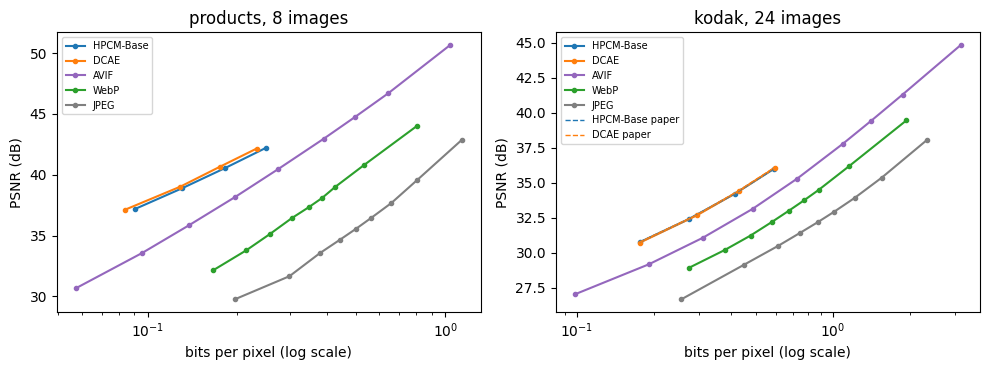

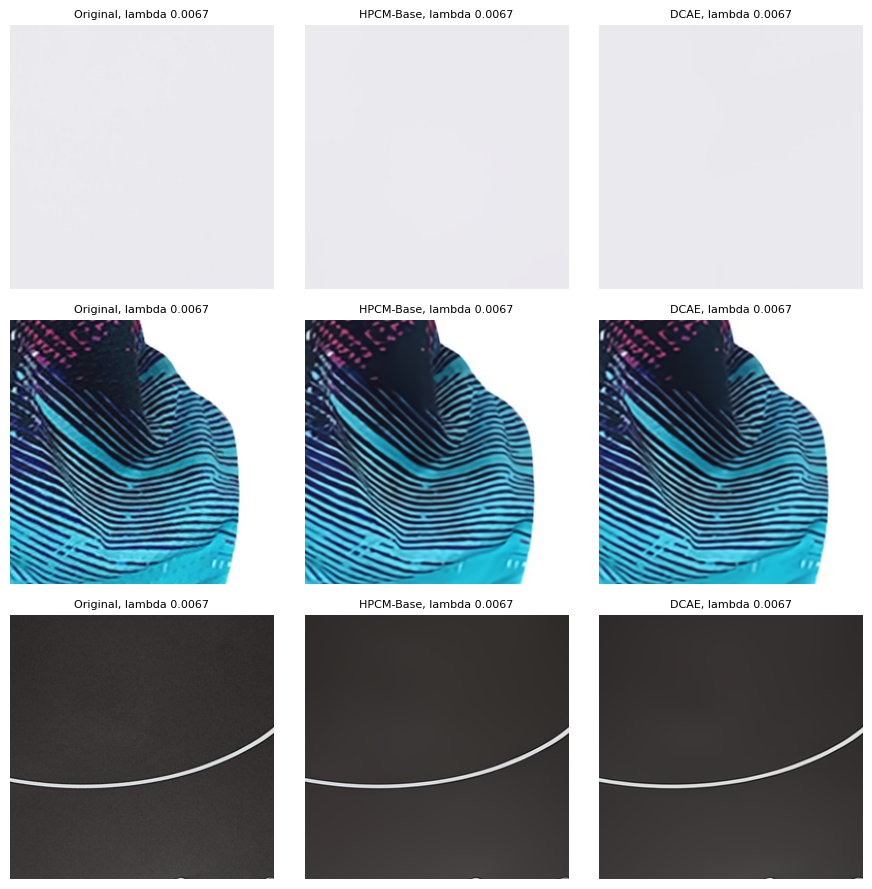

In [ ]:
# rate-distortion curves, with each paper's Kodak curve dashed
colours = {A: "tab:blue", B: "tab:orange", "AVIF": "tab:purple", "WebP": "tab:green", "JPEG": "grey"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, s in zip(axes, ("products", "kodak")):
    for label, colour in colours.items():
        c = curves[(curves.set == s) & (curves.codec == label)].sort_values("bpp")
        ax.plot(c.bpp, c.psnr, marker="o", ms=3, color=colour, label=label)
    if s == "kodak":
        for label in (A, B):
            ax.plot(*PAPER_KODAK[label], ls="--", lw=1, color=colours[label], label=f"{label} paper")
    ax.set_xscale("log")
    ax.set_xlabel("bits per pixel (log scale)")
    ax.set_ylabel("PSNR (dB)")
    ax.set_title(f"{s}, {(images.set == s).sum()} images")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "fig_rd_curves.png", dpi=150)
plt.show()


# a square crop around the centre of the product
def crop_box(path, half=128):
    ys, xs = np.where(product_mask(Image.open(path)))
    cx, cy = int(xs.mean()), int(ys.mean())
    return (max(0, cx - half), max(0, cy - half), max(0, cx - half) + 2 * half, max(0, cy - half) + 2 * half)


# crops of three product photos: original, HPCM-Base and DCAE at lambda 0.0067
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, img_id in enumerate(products[:3]):
    path = images.set_index("image").loc[img_id, "path"]
    box = crop_box(path)
    for j, (title, p) in enumerate([("Original", path), (A, OUT / "decoded" / f"hpcm_{img_id}.png"), (B, OUT / "decoded" / f"dcae_{img_id}.png")]):
        axes[i][j].imshow(Image.open(p).crop(box))
        axes[i][j].set_title(f"{title}, lambda 0.0067", fontsize=8)
        axes[i][j].axis("off")
fig.tight_layout()
fig.savefig(OUT / "fig_crops.jpg", dpi=120)
plt.show()

## My ratings
The assignment specification update of 26 October allows my own evaluation as user feedback. For the 8 product photos a 384 px crop of the original and of both
decoded images (lambda 0.0067) is saved, the decoded ones as X and Y in a random order; the key goes in a separate file
that I only open after rating. Question: at full zoom, how close is it to the original? (1 = clearly worse, 5 = can't
tell them apart). I also time each comparison (`seconds_to_check`), which shows how hard the differences are to see.

In [ ]:
# blind rating files: the 8 product photos, a crop of the original plus both decoded images as X and Y in a random order
(OUT / "rating").mkdir(exist_ok=True)
key = []
for i, img_id in enumerate(products, 1):
    swap = random.Random(i).random() < 0.5
    x, y = (B, A) if swap else (A, B)
    path = images.set_index("image").loc[img_id, "path"]
    box = crop_box(path, half=192)
    Image.open(path).crop(box).save(OUT / "rating" / f"item{i:02d}_original.png")
    for label, system in (("X", x), ("Y", y)):
        Image.open(OUT / "decoded" / f"{'hpcm' if system == A else 'dcae'}_{img_id}.png").crop(box).save(OUT / "rating" / f"item{i:02d}_{label}.png")
    key.append({"item": i, "image": img_id, "X": x, "Y": y})
# the key and an empty ratings sheet; I filled in the sheet before opening the key
pd.DataFrame(key).to_csv(OUT / "rating" / "key.csv", index=False)
pd.DataFrame({"item": range(1, len(key) + 1), "score_X": "", "score_Y": "", "seconds_to_check": ""}).to_csv(OUT / "rating" / "my_ratings.csv", index=False)

**Note:** this cell ran during the Kaggle run, before I did the blind ratings, so it prints "ratings not filled in yet". That is expected: the ratings had to come after the outputs were saved and before the key was opened. My ratings and their results are in the **last cell** of this notebook, which I ran on Google Colab afterwards.

In [ ]:
# run this after filling in rating/my_ratings.csv
r = pd.read_csv(OUT / "rating" / "my_ratings.csv").merge(pd.read_csv(OUT / "rating" / "key.csv"))
if r.score_X.notna().all():
    scores_r = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1), r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
    print(scores_r.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1))
    print(f"time per comparison: {r.seconds_to_check.mean():.1f} s")
else:
    print("ratings not filled in yet")

ratings not filled in yet


## Run record
Save the date, GPU, package versions, both commits and the lambdas to `run_info.json`, then zip the results folder for download.

In [ ]:
# record the run settings and zip the results folder
pd.Series({"date": time.ctime(), "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__,
           "compressai": version("compressai"), "imagecodecs": imagecodecs.__version__,
           "hpcm commit": REPOS["hpcm"][1], "dcae commit": REPOS["dcae"][1], "lambdas": LAMBDAS}).to_json(OUT / "run_info.json")
shutil.make_archive("/kaggle/working/pair4_results", "zip", OUT)

'/kaggle/working/pair4_results.zip'

## My ratings: results
I ran this cell on Google Colab after the Kaggle run, once I had filled in `my_ratings.csv` without looking at `key.csv`. It joins my scores to the key and compares the two codecs.

In [1]:
# my ratings, added after the Kaggle run (my_ratings.csv and key.csv from rating/)
import pandas as pd
from pathlib import Path
from scipy.stats import wilcoxon


# find an uploaded file anywhere under /content
def find(name):
    hits = sorted(Path("/content").rglob(name))
    if not hits:
        raise FileNotFoundError(f"{name} not found: upload it with the folder icon on the left and wait for the upload to finish")
    return hits[0]


# join my scores to the key so each score is linked to its codec
r = pd.read_csv(find("my_ratings.csv")).merge(pd.read_csv(find("key.csv")))
r = r.dropna(subset=["score_X", "score_Y"])   # any item whose crop showed only background is left out
scores = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1),
                    r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
summary = scores.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1)
display(summary.round(2))

# paired comparison of my scores, item by item
wide = scores.assign(item=list(r.item) * 2).pivot(index="item", columns="system", values="score")
d = wide["HPCM-Base"] - wide["DCAE"]
print(len(r), "items rated")
print("items where HPCM-Base scored higher:", (d > 0).sum(), "| DCAE higher:", (d < 0).sum(), "| ties:", (d == 0).sum())
print("Wilcoxon p on scores:", round(wilcoxon(d).pvalue, 3) if (d != 0).any() else "all ties")
print(f"time per comparison: {r.seconds_to_check.mean():.1f} s")
summary.to_csv("user_ratings_summary.csv")

,mean score,share rated 4 or 5
system,,
DCAE,4.43,0.86
HPCM-Base,4.29,0.86


7 items rated
items where HPCM-Base scored higher: 1 | DCAE higher: 2 | ties: 4
Wilcoxon p on scores: 1.0
time per comparison: 9.0 s
